# Cobertura conforme y estimación de desempeño sin etiquetas

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular un cuantil conforme dividido y su rango $k$ de forma exacta, y ver la trampa de coma flotante que vuelve errado el rango ingenuo para algunos pares $(n, \alpha)$;
- construir conjuntos de predicción para un modelo de PD binario y medir su cobertura empírica fuera de tiempo contra la meta $1 - \alpha$;
- leer la prueba de cobertura contra la ley que la cobertura realmente tiene dado el tamaño de la ventana de calibración (una Beta-Binomial), y ver en qué se diferencia de la forma binomial;
- estimar el AUC y los conteos de confusión de un modelo solo desde probabilidades calibradas (CBPE) mientras maduran los incumplimientos, enunciar sus cuatro supuestos y verla fallar cuando uno de ellos falla;
- leer la variante versionada del desplazamiento de la Reserva Federal del caso C20 y reconstruir sus filas de cobertura con el motor.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ml import cbpe, conformal, plants
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import ml as vml
from scipy import stats

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

- **La planta de ruptura de intercambiabilidad** del motor (`ExchangeabilityBreakPlant`): una ventana de calibración de $10n$ deudores y una ventana de prueba de $n$, la PD de cada deudor sacada de una ley Beta(2, 5), las etiquetas de calibración Bernoulli(PD) y las de prueba Bernoulli de la PD desplazada por un `drift` en log-odds. `drift = 0` es intercambiabilidad, la nula. La planta da la cobertura exacta del conjunto conforme dividido en el cuantil poblacional, así que una cobertura medida puede compararse con una conocida.
- **La variante versionada del desplazamiento de la Reserva Federal del caso C20** (`data/derived/C20/fed-shift.json`; propietario: este repositorio). Un modelo LightGBM ajustado con los datos de quiebras polacas de UCI (CC BY 4.0, clase mirror-allowed) se evalúa sobre una reserva bloqueada de 3.151 empresas, una vez tal cual (la ventana base) y bajo tres desplazamientos sintéticos dimensionados por el PSI de la calificación corporativa entre las carteras típica y de mayor riesgo de la Reserva Federal (dominio público). Las etiquetas nunca se mueven. Los conjuntos conformes salen de una ventana de calibración de 1.471 empresas. La primera celda abre el documento e imprime el motor que lo horneó.

In [2]:
# Abrir la variante de desplazamiento versionada e imprimir el motor que la horneó, el conjunto de evaluación y las ventanas
shift = json.loads((ROOT / "data" / "derived" / "C20" / "fed-shift.json").read_text(encoding="utf-8"))
print("horneado con riskvalidation", shift["provenance"]["riskvalidation_version"])
synthetic = shift["outputs"]["synthetic_shift"]
print("conjunto de evaluación:", synthetic["evaluation_set"])
for s in synthetic["shifts"]:
    print(f'  {s["shift_id"]:24s} PSI {s["psi"]:.4f} | AUC con etiquetas {s["metric"]["auc"]:.4f}')

horneado con riskvalidation 0.9.0
conjunto de evaluación: uci-polish-3year-holdout (3,151 rows, locked)
  fed-higher-risk-x0.25    PSI 0.3402 | AUC con etiquetas 0.7898
  fed-higher-risk-x0.5     PSI 0.6804 | AUC con etiquetas 0.7731
  fed-higher-risk-x1       PSI 1.3609 | AUC con etiquetas 0.6914


## Método

### Paso 1: el cuantil conforme dividido y su rango

Se toman $n$ puntos de calibración con puntajes de no conformidad $s_i$. Para un modelo binario con PD $p_i$ y etiqueta $y_i$ el puntaje es la probabilidad que el modelo dio a la etiqueta equivocada, $s_i = 1 - \hat{p}_{y_i}(x_i)$: $1 - p_i$ cuando $y_i = 1$ y $p_i$ cuando $y_i = 0$. El cuantil conforme es el $k$-ésimo menor puntaje,

$$k = \left\lceil (n+1)(1-\alpha) \right\rceil, \qquad \hat{q} = s_{(k)}, \qquad C(x) = \{ y : 1 - \hat{p}_y(x) \le \hat{q} \},$$

y bajo intercambiabilidad el conjunto cubre la etiqueta verdadera con probabilidad de al menos $1 - \alpha$ (Angelopoulos y Bates, 2021; Vovk, Gammerman y Shafer, 2022). Si $k > n$ el cuantil es $+\infty$ y el conjunto es toda etiqueta.

El rango es un entero calculado desde un decimal, y los flotantes lo traicionan. Para $n = 149$ y $\alpha = 0{,}18$ el producto $150 \times (1 - 0{,}18)$ es exactamente 123, pero en coma flotante es $123{,}00000000000001$, así que un techo ingenuo da 124 y el cuantil queda un estadístico de orden más alto. El motor calcula $k$ sobre el decimal exacto de $\alpha$. MAPIE, una implementación de referencia, usa el $\lceil\cdot\rceil$ de la misma expresión con la regla de cuantil `higher`, que puede devolver el $(k+1)$-ésimo estadístico de orden, así que las pruebas del motor comparan con MAPIE teniendo eso en cuenta. La celda siguiente muestra la trampa con 149 puntajes.

In [3]:
# La trampa de flotantes: el rango ingenuo para 149 puntajes con alfa 0,18 y el estadístico de orden que devuelve el motor
rng = np.random.default_rng(7)
scores = np.sort(rng.random(149))
alpha = 0.18
naive_k = math.ceil((149 + 1) * (1 - alpha))
print("(n + 1) * (1 - alpha) en coma flotante:", repr((149 + 1) * (1 - alpha)), "| rango ingenuo:", naive_k)
q_engine = conformal.split_conformal_quantile(scores, alpha)
rank_engine = int(np.searchsorted(scores, q_engine)) + 1
print("rango que usó el motor:", rank_engine, "| es el puntaje de rango 123:", ("sí" if q_engine == scores[122] else "no"))
print("k > n da un cuantil infinito:", conformal.split_conformal_quantile(scores[:5], 0.1))

(n + 1) * (1 - alpha) en coma flotante: 123.00000000000001 | rango ingenuo: 124
rango que usó el motor: 123 | es el puntaje de rango 123: sí
k > n da un cuantil infinito: inf


### Paso 2: conjuntos de predicción y cobertura fuera de tiempo

En la planta con `drift = 0` las ventanas de calibración y de prueba son intercambiables. La celda siguiente calcula los puntajes de la ventana de calibración, el cuantil para $\alpha = 0{,}1$ (cobertura meta 0,9), los conjuntos de la ventana de prueba y su cobertura empírica, e imprime los valores exactos de la planta a su lado. Luego lo mismo con `drift = 1`, donde la tasa de etiquetas de la ventana de prueba se movió una unidad de log-odds después de la ventana de calibración.

In [4]:
# Puntajes, cuantil, conjuntos y cobertura empírica en la planta sin deriva y con deriva, junto a los valores exactos
ALPHA = 0.1
windows = {}
for label, drift in (("sin deriva", 0.0), ("deriva de 1", 1.0)):
    plant = plants.ExchangeabilityBreakPlant(n=2000, drift=drift, seed=5)
    d = plant.sample()
    cal_scores = np.where(d["y_cal"] == 1, 1.0 - d["p_cal"], d["p_cal"])
    qhat = conformal.split_conformal_quantile(cal_scores, ALPHA)
    sets = conformal.conformal_sets(d["p_test"], qhat)
    cover = conformal.conformal_coverage(sets, d["y_test"], ALPHA, n_cal=len(cal_scores))
    windows[label] = (plant, d, sets, cover)
    exact = plant.truth(ALPHA)
    print(f"{label:16s} n_cal {cover.n_cal} k {cover.k} m {cover.n} | qhat {qhat:.4f} (poblacional {exact['qhat']:.4f}) | cobertura {cover.coverage:.4f} (exacta {exact['coverage_test']:.4f}, meta {cover.target:.2f})")

sin deriva       n_cal 20000 k 18001 m 2000 | qhat 0.7075 (poblacional 0.7051) | cobertura 0.8985 (exacta 0.9000, meta 0.90)
deriva de 1      n_cal 20000 k 18001 m 2000 | qhat 0.7075 (poblacional 0.7051) | cobertura 0.7995 (exacta 0.8010, meta 0.90)


### Paso 3: la ley del conteo cubierto

Dada una ventana de calibración de $n_{\mathrm{cal}}$ puntos, la cobertura del conjunto no es un número fijo: es aleatoria, porque $\hat{q}$ es un estadístico de orden aleatorio. Bajo intercambiabilidad sigue

$$\text{cobertura} \sim \mathrm{Beta}(k,\; n_{\mathrm{cal}} + 1 - k), \qquad k = \lceil (n_{\mathrm{cal}}+1)(1-\alpha) \rceil,$$

de modo que el número $c$ de los $m$ puntos de prueba cuyo conjunto contiene la etiqueta verdadera es **Beta-Binomial**$(m, k, n_{\mathrm{cal}} + 1 - k)$. El valor p de dos colas es la probabilidad total de los conteos no más probables que $c$ (la regla de mínima verosimilitud de una prueba exacta). La forma del dossier prueba en cambio $c$ contra $\mathrm{Binomial}(m, 1-\alpha)$, que ignora la aleatoriedad de $\hat{q}$ y rechaza demasiado cuando $m$ no es pequeño frente a $n_{\mathrm{cal}}$. El motor calcula ambos y deja que la Beta-Binomial gobierne la luz (roja bajo 0,01, ámbar bajo 0,05); el valor p binomial queda a su lado como la forma del dossier. La celda siguiente imprime ambos para las dos ventanas del paso 2, y la luz que da la prueba del motor.

In [5]:
# Ambos valores p y la luz del motor para las dos ventanas
for label, (plant, d, sets, cover) in windows.items():
    result = vml.conformal_coverage("planta-intercambiabilidad", cover)
    print(f"{label:16s} p Beta-Binomial {cover.p_value:.4g} | p binomial {cover.p_value_binomial:.4g} | luz {result.light.value} | estadístico (cobertura menos meta) {result.statistic:.4f}")

sin deriva       p Beta-Binomial 0.8311 | p binomial 0.823 | luz green | estadístico (cobertura menos meta) -0.0015
deriva de 1      p Beta-Binomial 1.494e-36 | p binomial 6.519e-41 | luz red | estadístico (cobertura menos meta) -0.1005


### Paso 4: las ventanas versionadas, reconstruidas

La prueba lee solo el **conteo cubierto** $c$ de $m$, la meta y el tamaño de calibración. El documento versionado guarda, para la ventana base y las tres ventanas desplazadas (y las cuatro juntas), la cobertura, $n_{\mathrm{cal}}$ = 1.471, $k$ = 1.325 y ambos valores p. La celda siguiente reconstruye un arreglo de conjuntos que contiene exactamente el conteo versionado, llama a la función de cobertura y a la prueba del motor, y compara los valores p y la luz con la fila versionada. Cualquier diferencia sería un cambio del motor desde el horneado.

In [6]:
# Reconstruir un arreglo de conjuntos con el conteo cubierto versionado, llamar al motor y comparar con las filas versionadas
rows = [t for t in shift["tests"] if t["test_id"] == "ml.conformal_coverage"]
print("filas versionadas:", len(rows), "| alpha", shift["outputs"]["synthetic_shift"]["label_free"]["conformal"]["alpha"])
rebuilt = {}
for t in rows:
    m = t["n"]
    c = round(t["metric"] * m)
    hit = np.zeros(m, dtype=bool)
    hit[:c] = True
    sets = np.column_stack([hit, np.zeros(m, dtype=bool)])
    cover = conformal.conformal_coverage(sets, np.zeros(m, dtype=int), 0.1, n_cal=t["extras"]["n_cal"])
    again = vml.conformal_coverage(t["model_id"], cover)
    rebuilt[t["segment"]] = (t, cover)
    same = math.isclose(again.p_value, t["p_value"], rel_tol=1e-9) and math.isclose(cover.p_value_binomial, t["extras"]["p_value_binomial"], rel_tol=1e-9) and again.light.value == t["light"]
    print(f'{t["segment"]:26s} m {m:6d} cobertura {cover.coverage:.4f} | p BB {cover.p_value:.3g} | p binomial {cover.p_value_binomial:.3g} | luz {again.light.value:5s} | igual a la versionada {"sí" if same else "no"}')

filas versionadas: 5 | alpha 0.1
window:baseline            m   3151 cobertura 0.8946 | p BB 0.523 | p binomial 0.313 | luz green | igual a la versionada sí
window:fed-higher-risk-x0.25 m   3151 cobertura 0.7509 | p BB 2.13e-35 | p binomial 3.69e-127 | luz red   | igual a la versionada sí
window:fed-higher-risk-x0.5 m   3151 cobertura 0.7099 | p BB 4.56e-52 | p binomial 1.19e-194 | luz red   | igual a la versionada sí
window:fed-higher-risk-x1  m   3151 cobertura 0.8800 | p BB 0.0372 | p binomial 0.000258 | luz amber | igual a la versionada sí
window:pooled              m  12604 cobertura 0.8089 | p BB 2.86e-20 | p binomial 2.16e-207 | luz red   | igual a la versionada sí


### Paso 5: CBPE, el AUC sin etiquetas

Mientras maduran los incumplimientos, un modelo tiene puntajes y no etiquetas. La estimación de desempeño basada en confianza (CBPE, la idea de NannyML) trata una probabilidad **calibrada** $p_j$ como la probabilidad de que su propia etiqueta sea 1. Para la etiqueta predicha $\hat{y}_j = \mathbb{1}[p_j \ge t]$ la probabilidad de que la predicción sea correcta es

$$P(\hat{y}_j = y_j) = 1 - |\hat{y}_j - p_j|,$$

de modo que los conteos esperados a un umbral $t$ son $TP = \sum_{\hat y=1} p_j$, $FP = \sum_{\hat y=1} (1 - p_j)$, $TN = \sum_{\hat y=0} (1 - p_j)$ y $FN = \sum_{\hat y=0} p_j$. Repetir sobre umbrales en $[0,1]$ da $\mathrm{TPR} = TP/(TP+FN)$ y $\mathrm{FPR} = FP/(FP+TN)$ esperadas, y el área trapezoidal bajo ellas es el AUC estimado. **No se lee ninguna etiqueta.** La estimación descansa en cuatro supuestos que el motor registra con cada estimación: probabilidades calibradas, sin deriva de concepto, sin extrapolación a regiones no vistas y una muestra adecuada. Complementa, y nunca reemplaza, el backtesting. La celda siguiente calcula la confusión a un umbral, el AUC estimado para las plantas del paso 2, y el AUC con etiquetas de las mismas filas.

In [7]:
# Confusión esperada a un umbral, luego el AUC estimado sin etiquetas contra el AUC con etiquetas para ambas plantas
for label, (plant, d, sets, cover) in windows.items():
    p = d["p_test"]
    conf = cbpe.cbpe_confusion(p, 0.25)
    estimate = cbpe.cbpe_auc(p)
    labelled = float(disc.disc_auc(p, d["y_test"]).metric)
    print(f"{label:16s} confusión esperada al umbral tp {conf.tp:.1f} fp {conf.fp:.1f} tn {conf.tn:.1f} fn {conf.fn:.1f} | suma {conf.tp + conf.fp + conf.tn + conf.fn:.0f}")
    print(f"                 AUC estimado sin etiquetas {estimate.estimated_auc:.4f} | AUC con etiquetas {labelled:.4f}")
print("la estimación se etiqueta:", estimate.label, "|", estimate.assumptions)

sin deriva       confusión esperada al umbral tp 437.4 fp 635.6 tn 789.3 fn 137.7 | suma 2000
                 AUC estimado sin etiquetas 0.7223 | AUC con etiquetas 0.7155
deriva de 1      confusión esperada al umbral tp 437.4 fp 635.6 tn 789.3 fn 137.7 | suma 2000
                 AUC estimado sin etiquetas 0.7223 | AUC con etiquetas 0.7306
la estimación se etiqueta: estimate | ('calibrated-probabilities', 'no-concept-drift', 'no-extrapolation', 'adequate-sample')


La estimación es la misma para ambas ventanas cuando las probabilidades son las mismas, hagan lo que hagan las etiquetas: esa es su fortaleza (no necesita etiqueta) y su límite (no puede ver un cambio en el vínculo entre puntaje y resultado, que es el segundo supuesto). Por eso la fila de prueba del motor **nunca toma una luz**: `cbpe_estimate` devuelve `not_evaluated` con la estimación y sus cuatro supuestos en el resultado, de modo que nunca mueve la peor luz de una batería. La celda siguiente muestra la fila, y la estimación versionada sobre el desplazamiento de la Reserva Federal junto al AUC calculado con etiquetas.

In [8]:
# La fila del motor de la estimación, y la estimación versionada contra el AUC versionado con etiquetas en el desplazamiento completo
row = vml.cbpe_estimate("planta-intercambiabilidad", estimate)
print("luz:", row.light.value, "| estadístico:", row.statistic, "| AUC estimado en extras:", round(row.extras["estimate"]["estimated_auc"], 4))
label_free = synthetic["label_free"]["cbpe"]
full_shift = next(s for s in synthetic["shifts"] if s["shift_id"].endswith("x1"))
committed = next(t for t in shift["tests"] if t["test_id"] == "ml.cbpe_estimate")
print(f'fila versionada: {committed["light"]} | estimación {label_free["estimated_auc"]:.4f} | AUC calculado con etiquetas en el desplazamiento completo {full_shift["metric"]["auc"]:.4f}')

luz: not_evaluated | estadístico: nan | AUC estimado en extras: 0.7223
fila versionada: not_evaluated | estimación 0.8481 | AUC calculado con etiquetas en el desplazamiento completo 0.6914


### Paso 6: la evidencia, dibujada

Izquierda: la cobertura empírica de cada ventana versionada contra la meta 0,9. Derecha: el AUC estimado sin etiquetas junto al AUC calculado con etiquetas, para las dos ventanas de la planta y para el desplazamiento completo versionado.

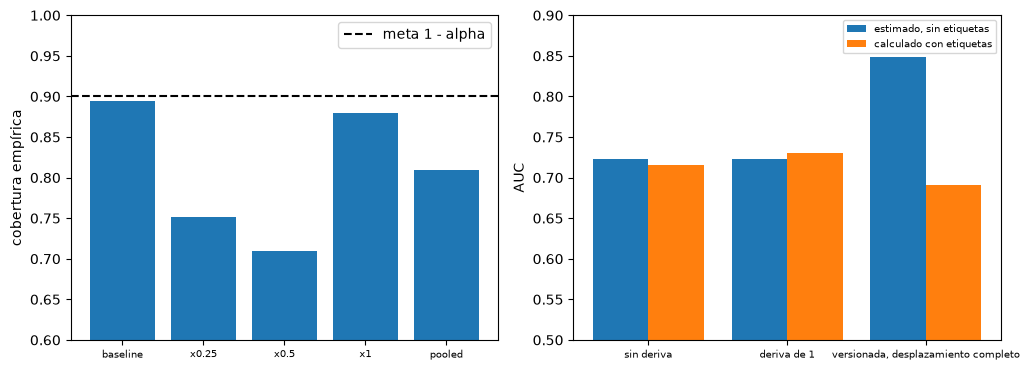

In [9]:
# Izquierda: cobertura versionada por ventana con la meta; derecha: AUC estimado contra AUC con etiquetas
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.8))
names = [seg.replace("window:", "").replace("fed-higher-risk-", "") for seg in rebuilt]
left.bar(names, [cover.coverage for _, cover in rebuilt.values()], color="tab:blue")
left.axhline(0.9, color="black", linestyle="--", label="meta 1 - alpha")
left.set_ylim(0.6, 1.0)
left.set_ylabel("cobertura empírica")
left.tick_params(axis="x", labelsize=7)
left.legend()
groups, estimated, labelled = [], [], []
for label, (plant, d, sets, cover) in windows.items():
    groups.append(label)
    estimated.append(cbpe.cbpe_auc(d["p_test"]).estimated_auc)
    labelled.append(float(disc.disc_auc(d["p_test"], d["y_test"]).metric))
groups.append("versionada, desplazamiento completo")
estimated.append(label_free["estimated_auc"])
labelled.append(full_shift["metric"]["auc"])
position = np.arange(len(groups))
right.bar(position - 0.2, estimated, width=0.4, label="estimado, sin etiquetas")
right.bar(position + 0.2, labelled, width=0.4, label="calculado con etiquetas")
right.set_xticks(position)
right.set_xticklabels(groups, fontsize=7)
right.set_ylim(0.5, 0.9)
right.set_ylabel("AUC")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Resultados

- **El rango es un problema de enteros.** Para 149 puntajes con $\alpha = 0{,}18$ el producto en coma flotante es 123,00000000000001, un techo ingenuo da 124, y el motor usa el puntaje de rango 123. Con menos puntos de calibración que los que exige el rango, el cuantil es infinito y el conjunto es toda etiqueta.
- **Los conjuntos cubren lo que prometen bajo intercambiabilidad, y no después de una deriva.** En la planta los conjuntos cubren 0,8985 de la ventana de prueba sin deriva (el valor exacto es 0,9000, la meta 0,90; p Beta-Binomial = 0,8311, verde) y 0,7995 con una deriva de una unidad de log-odds (exacto 0,8010; p = 1,494e-36, rojo). El cuantil es el mismo en ambos (0,7075): la ventana de calibración no cambió, la de prueba sí.
- **La ley del conteo importa cuando la ventana de prueba no es pequeña frente a la de calibración.** En la planta ($n_{\mathrm{cal}} = 20.000$, $m = 2.000$) los dos valores p son cercanos (0,8311 y 0,823). En la ventana base versionada ($n_{\mathrm{cal}} = 1.471$, $m = 3.151$) son 0,523 (Beta-Binomial) y 0,313 (binomial): la forma binomial ignora la aleatoriedad del cuantil de calibración. Reconstruido desde el conteo cubierto versionado, el motor reproduce cada valor p y cada luz versionados: base 0,8946 (verde), los tres desplazamientos 0,7509 y 0,7099 (rojo) y 0,8800 (ámbar, p = 0,0372), y las cuatro ventanas juntas 0,8089 sobre 12.604 filas (rojo). Los valores p binomiales (3,69e-127 para el primer desplazamiento) dicen lo mismo en un tono más fuerte, que es lo que los hace una mala guía de tamaño. La cobertura no es monótona en el desplazamiento: el pipeline dimensionó los desplazamientos por el PSI del puntaje, y el documento no explica por qué el mayor pierde menos cobertura que los intermedios.
- **CBPE lee probabilidades y nada más.** Los conteos de confusión esperados suman las 2.000 filas; el AUC estimado es 0,7223 para ambas ventanas de la planta, porque las probabilidades son las mismas, hagan lo que hagan las etiquetas. El AUC calculado con etiquetas es 0,7155 sin deriva y 0,7306 con ella: una deriva en la log-odds es casi monótona y mueve poco el orden, así que la estimación queda cerca en ambas ventanas, y lo que cambia la deriva es la calibración, que la prueba de cobertura ve (0,8985 contra 0,7995) y el AUC no. En el desplazamiento completo versionado la estimación es 0,8481 y el AUC calculado con etiquetas es 0,6914: la estimación queda 0,1567 por encima, porque las filas desplazadas salen de la región en que se ajustó el modelo (el tercer supuesto).
- **El motor nunca deja que la estimación tome una luz.** La fila es `not_evaluated`, su estadístico no es un número, y el AUC estimado y sus cuatro supuestos están en el resultado. La fila versionada tiene la misma forma.

Lo que los resultados no muestran: la planta es sintética y su deriva es elegida; los desplazamientos versionados son desplazamientos sintéticos de una reserva real dimensionados por el PSI de una calificación, así que las pérdidas de cobertura dicen qué hace la prueba, no cómo se desplaza una cartera real; la garantía conforme necesita intercambiabilidad, y una pérdida de cobertura se lee como síntoma de su falla, nunca como prueba; y los puntos de corte (0,05, 0,01) son convenciones.

## Resumen

- El cuantil conforme dividido es el $k$-ésimo menor puntaje de calibración con $k = \lceil (n+1)(1-\alpha) \rceil$ calculado sobre el decimal exacto de $\alpha$; los conjuntos cubren al menos $1 - \alpha$ bajo intercambiabilidad.
- El conteo cubierto de la ventana de prueba es Beta-Binomial dado el tamaño de calibración; la luz del motor lee ese valor p, y el valor p binomial del dossier queda a su lado.
- Fuera de tiempo, una cobertura bajo la meta es un síntoma de intercambiabilidad rota; las ventanas versionadas de la Reserva Federal pierden cobertura en tres de cuatro ventanas, y el motor reproduce cada valor p y cada luz versionados.
- CBPE estima el AUC solo desde probabilidades calibradas bajo cuatro supuestos, siempre etiquetada como estimación; su fila del motor nunca toma una luz. Queda 0,1567 por encima en el desplazamiento completo versionado, donde las filas desplazadas salen de la región ajustada.
- La cobertura ve un cambio de calibración que el AUC no ve; las dos responden preguntas distintas.

**Qué probar después.** El cuaderno 05 compara un campeón con un retador por un bootstrap pareado del Brier. El cuaderno 09 mide el tamaño de la prueba de cobertura conforme con la nula binomial y con la Beta-Binomial.

## Referencias

- Angelopoulos, A. N. y Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- Vovk, V., Gammerman, A. y Shafer, G. (2022), Algorithmic Learning in a Random World, 2.ª edición, Springer. https://doi.org/10.1007/978-3-031-06649-8
- NannyML, cómo funciona la estimación de desempeño basada en confianza (CBPE). https://nannyml.readthedocs.io/en/stable/how_it_works/performance_estimation.html
- BCE (2025), Guía de modelos internos, los párrafos sobre la aleatoriedad del entrenamiento, el sobreajuste, la explicabilidad y la justificación de la complejidad (43, 59, 60, 62, 64 a 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- EBA (2023), Follow-up report on machine learning for IRB models, EBA/REP/2023/28. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2023/1061483/Follow-up%20report%20on%20machine%20learning%20for%20IRB%20models.pdf
- MAPIE (BSD-3-Clause), predicción conforme para scikit-learn. https://github.com/scikit-learn-contrib/MAPIE